# 04-3. 결빙 분류: 검증 지점 평가와 저장

04의 3~5장입니다. 04-1에서 정한 최종 모델과 임계값으로 검증 지점 3곳의 10분 단위 결빙을 예측하고, 일별 F1, Precision, Recall과 평가기간 평균을 냅니다.

02-2의 지점 변수, 03-3의 추정 노면온도, 04-1의 후보 모델과 설정을 읽습니다. 성능지표와 10분 단위 예측은 `data/results/icing_scores.csv`, `icing_daily_scores.csv`, `icing_10min_scores.csv`, `icing_holdout_10min.csv`에 저장합니다. 제출 항목을 모은 표는 `holdout_submission_10min.csv`이고 그림은 `figures/icing_holdout_12410.png`입니다.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import json
import warnings

import joblib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib import font_manager

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
SEED = 42

In [3]:
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet")
sf = sf.merge(pd.read_parquet(config.PROCESSED_DIR / "station_estimates.parquet"), on=["stn", "time"])
sf["rst_dpd"] = sf["rst_est"] - sf["td"]  # 추정 노면온도 - 이슬점 (04-1과 같음)
sf["date"] = sf["time"].dt.normalize()
cv = json.load(open(config.PROCESSED_DIR / "icing_cv.json", encoding="utf-8"))  # 04-1에서 정한 설정
CLS_FEATURES, CANDIDATES, thresholds, FINAL = cv["features"], cv["candidates"], cv["thresholds"], cv["final"]
THRESHOLD = thresholds[FINAL]
stations = pd.read_parquet(config.PROCESSED_DIR / "stations.parquet").set_index("stn")
holdout = sf[sf["stn"].isin(config.HOLDOUT_STATIONS)].reset_index(drop=True)
full_models = joblib.load(config.PROCESSED_DIR / "icing_models.joblib")  # 학습 지점 14곳 전체로 학습한 후보 모델
model = full_models[FINAL]
print(f"최종 모델: {FINAL} (임계값 {THRESHOLD:.3f}), 검증 지점 {holdout.shape}")

최종 모델: LightGBM(결빙관련 라벨) (임계값 0.728), 검증 지점 (103680, 50)


학습 모델의 확률과 규칙 기반, Bonanno 결빙 기준, 서리 조건의 판정 함수입니다(04-1의 1장과 같은 정의).

In [4]:
def predict_icing(model, df, features=CLS_FEATURES):
    """10분 단위 결빙 확률."""
    return model.predict_proba(df[features])[:, 1]


def rule_based(df):
    return ((df["rst_est"] <= 0) & (df["rh"] >= 80) & ((df["rain_hrs12h"] > 0) | (df["snow"] > 0))).to_numpy()


def bonanno_rule(df):
    """Bonanno et al.(2010): 노면에 수분이 있을 때 강수 중이면 노면 < 1°C, 강수가 없으면 노면 < 0°C에서 결빙."""
    raining = df["rain"] >= 0.5
    moist = raining | (df["rain_hrs12h"] > 0) | (df["snow"] > 0) | (df["rst_dpd"] <= 0)
    return (moist & np.where(raining, df["rst_est"] < 1, df["rst_est"] < 0)).to_numpy()


def frost_rule(df):
    """Jang(2024)의 서리 조건: 노면온도 ≤ 0°C 이고 노면온도 ≤ 이슬점."""
    return ((df["rst_est"] <= 0) & (df["rst_dpd"] <= 0)).to_numpy()


RULES = {"규칙 기반": rule_based, "Bonanno 결빙 기준": bonanno_rule, "서리 조건(Jang)": frost_rule}

## 3. 검증 지점 10분 단위 예측

In [5]:
holdout["prob"] = predict_icing(model, holdout)
holdout["pred"] = (holdout["prob"] >= THRESHOLD).astype(int)
RULE_COLS = {"규칙 기반": "pred_rule", "Bonanno 결빙 기준": "pred_bonanno", "서리 조건(Jang)": "pred_frost"}
for name, col in RULE_COLS.items():
    holdout[col] = RULES[name](holdout).astype(int)
OTHER_COLS = {}
for i, name in enumerate(n for n in CANDIDATES if n != FINAL):
    m = full_models[name]
    OTHER_COLS[name] = f"pred_other{i}"
    holdout[OTHER_COLS[name]] = (predict_icing(m, holdout) >= thresholds[name]).astype(int)
holdout.groupby("stn").agg(Ice관측=("ice", "sum"), Ice예측=("pred", "sum"), 최대확률=("prob", "max")).join(
    stations["name"])

,Ice관측,Ice예측,최대확률,name
stn,,,,
12410,64.0,379,0.941100,부곡교(도)
23402,0.0,304,0.942061,해전(도)
33411,0.0,543,0.956041,삼봉(도)


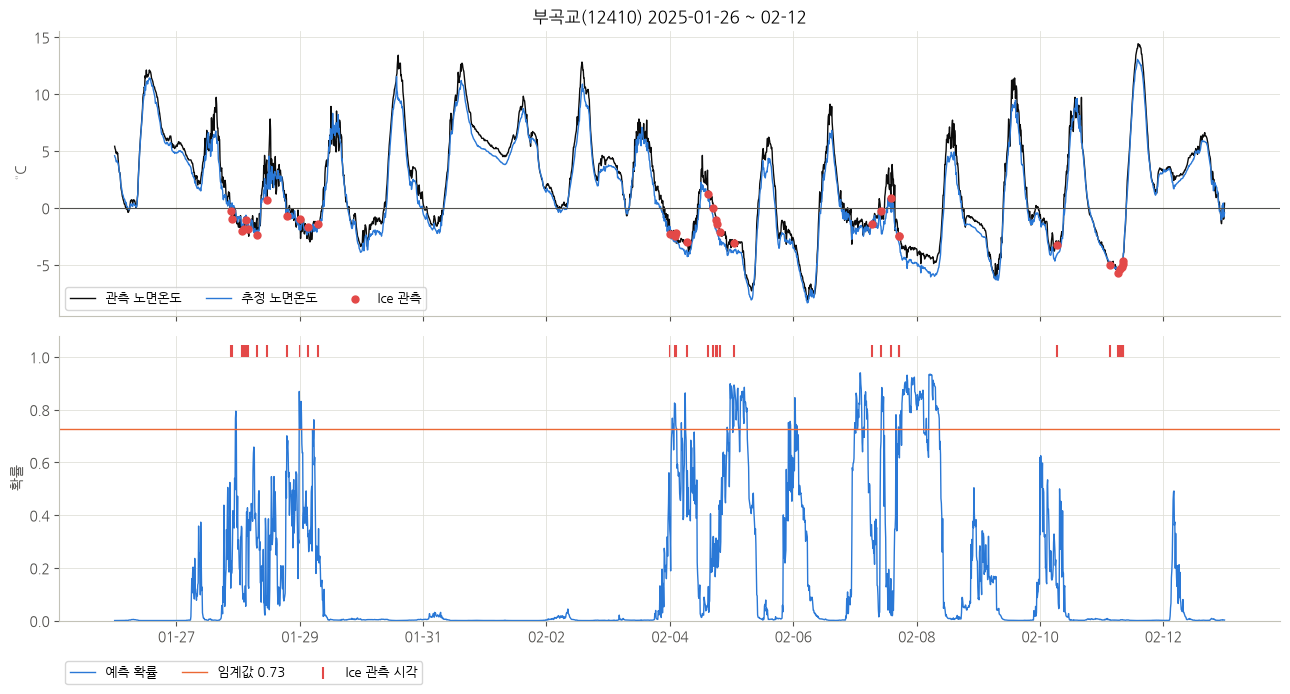

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
g = holdout[holdout["stn"] == 12410].set_index("time").loc["2025-01-26":"2025-02-12"]
axes[0].plot(g.index, g["rst"], color="#0b0b0b", linewidth=1, label="관측 노면온도")
axes[0].plot(g.index, g["rst_est"], color="#2a78d6", linewidth=1, label="추정 노면온도")
ice = g.index[g["ice"] == 1]
axes[0].scatter(ice, g.loc[ice, "rst"], color="#e34948", s=25, zorder=5, label="Ice 관측")
axes[0].axhline(0, color="#52514e", linewidth=0.8)
axes[0].set_ylabel("°C")
axes[0].legend(ncol=3, fontsize=9)
axes[1].plot(g.index, g["prob"], color="#2a78d6", linewidth=1, label="예측 확률")
axes[1].axhline(THRESHOLD, color="#eb6834", linewidth=1, label=f"임계값 {THRESHOLD:.2f}")
axes[1].scatter(ice, np.full(len(ice), 1.02), color="#e34948", marker="|", s=80, label="Ice 관측 시각")
axes[1].set_ylabel("확률")
axes[1].set_ylim(0, 1.08)
axes[1].legend(ncol=3, fontsize=9, loc="upper left", bbox_to_anchor=(0, -0.12))
axes[1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
axes[0].set_title("부곡교(12410) 2025-01-26 ~ 02-12")
plt.tight_layout()
fig.savefig(config.FIGURE_DIR / "icing_holdout_12410.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. 일별 성능지표 및 평균

일별 TP, FP, FN으로 F1, Precision, Recall을 구하고 평가기간 평균을 냅니다(지점별, 세 지점 평균). 기준은 QnA 답변을 따릅니다.

| 그날의 상황 | F1 | Precision | Recall | 근거 |
|---|---|---|---|---|
| 실제·예측 결빙이 모두 없음 | 평균에서 뺌 | 평균에서 뺌 | 평균에서 뺌 | QnA 2026-09-30·10-13 |
| 실제 결빙을 놓침 (예측 없음) | 0 | 평균에서 뺌 | 0 | QnA 2026-10-13 |
| 실제 결빙 없이 예측만 함 | 0 | 0 | 평균에서 뺌 | QnA 2026-11-03 |

평가 기간에 실제 결빙이 한 번도 없는 지점은 '산출불가'로 적고 세 지점 평균에서 뺍니다. 지표 산정에 쓴 지점 수와 평가 날짜 수를 함께 적습니다(QnA 2026-11-02·11-03).

평가 함수입니다. 일별 TP, FP, FN과 지표는 04-1의 0장과 같은 정의입니다.

In [7]:
def daily_icing_scores(df):
    """지점별 일별 TP, FP, FN, Precision, Recall, F1 (QnA 2026-09-30·10-13·11-03 기준).

    Args:
        df: stn, time, y_true(0/1), y_pred(0/1) 컬럼을 가진 10분 단위 DataFrame. y_true가 NaN인 시각은 뺀다.

    실제·예측 결빙이 모두 없는 날은 세 지표 모두 평균에서 뺀다 (NaN).
    결빙을 놓친 날은 Precision을 계산할 수 없어 평균에서 빼고, Recall·F1은 0이다.
    실제 결빙 없이 예측만 한 날은 Recall을 계산할 수 없어 평균에서 빼고, Precision·F1은 0이다.
    """
    d = df.dropna(subset=["y_true"]).copy()
    d["date"] = d["time"].dt.normalize()
    y, p = d["y_true"].astype(int), d["y_pred"].astype(int)
    d["TP"], d["FP"], d["FN"] = y & p, (1 - y) & p, y & (1 - p)
    day = d.groupby(["stn", "date"])[["TP", "FP", "FN"]].sum()
    tp, fp, fn = day["TP"], day["FP"], day["FN"]
    day["Precision"] = (tp / (tp + fp)).where(tp + fp > 0)
    day["Recall"] = (tp / (tp + fn)).where(tp + fn > 0)
    day["F1"] = (2 * tp / (2 * tp + fp + fn)).where(tp + fp + fn > 0)
    return day.reset_index()


def stations_with_ice(day):
    """실제 결빙이 한 번이라도 있는 지점. 나머지는 '산출불가'로 평균에서 뺀다 (QnA 2026-11-02·11-03)."""
    obs = (day["TP"] + day["FN"]).groupby(day["stn"]).sum()
    return obs.index[obs > 0]


SCORES = ["F1", "Precision", "Recall"]
COUNTS = ["평가일수", "Precision 평가일수", "Recall 평가일수", "결빙관측일수", "오탐일수", "활용 지점 수"]


def summarize_holdout(daily, names=None):
    """지점별 평가기간 평균과 지점 평균 행. 실제 결빙이 없는 지점은 지표가 비고(산출불가) 평균에서 빠진다."""
    g = daily.assign(obs_day=(daily["TP"] + daily["FN"]) > 0, fp_day=daily["FP"] > 0).groupby("stn")
    out = pd.DataFrame({
        "평가일수": g["F1"].count(), "Precision 평가일수": g["Precision"].count(), "Recall 평가일수": g["Recall"].count(),
        "결빙관측일수": g["obs_day"].sum(), "오탐일수": g["fp_day"].sum(),
        "F1": g["F1"].mean(), "Precision": g["Precision"].mean(), "Recall": g["Recall"].mean(),
    })
    none = ~out.index.isin(stations_with_ice(daily))
    out.loc[none, SCORES] = np.nan
    out.loc[none, ["평가일수", "Precision 평가일수", "Recall 평가일수"]] = 0
    used = out[~none]
    mean = used.sum(numeric_only=True).to_frame().T  # 일수는 합계, 지표는 활용 지점의 평균
    mean[SCORES] = used[SCORES].mean().to_numpy()
    mean.index = ["지점 평균"]
    mean["활용 지점 수"] = len(used)
    if names is not None:
        out.insert(0, "지점명", names.reindex(out.index))
        mean.insert(0, "지점명", f"{len(used)}개 지점 평균 (평가 {len(out)}개소 중)")
    return pd.concat([out, mean])


def show(table, digits=3):
    """값이 없는 지표를 '산출불가'로 표기한다."""
    counts = [c for c in COUNTS if c in table]
    return (table.round(digits).astype({c: "Int64" for c in counts}).astype({c: object for c in SCORES})
            .fillna({c: "산출불가" for c in SCORES}))


In [8]:
def holdout_daily(pred_col):
    return daily_icing_scores(holdout[["stn", "time"]].assign(y_true=holdout["ice"], y_pred=holdout[pred_col]))


names = stations["name"]
results = {label: summarize_holdout(holdout_daily(col), names)
           for label, col in [(FINAL, "pred"), *OTHER_COLS.items(), *RULE_COLS.items()]}
show(results[FINAL])


,지점명,평가일수,Precision 평가일수,Recall 평가일수,결빙관측일수,오탐일수,F1,Precision,Recall,활용 지점 수
12410,부곡교(도),30,22,19,19,22,0.028,0.025,0.187,<NA>
23402,해전(도),0,0,0,0,16,산출불가,산출불가,산출불가,<NA>
33411,삼봉(도),0,0,0,0,20,산출불가,산출불가,산출불가,<NA>
지점 평균,1개 지점 평균 (평가 3개소 중),30,22,19,19,22,0.028,0.025,0.187,1


삼봉(33411)과 해전(23402)은 평가기간 내내 Ice가 없어 지표를 계산할 수 없습니다. '산출불가'로 적고 평균에서 뺐습니다. 세 지점 평균은 부곡교 한 곳의 값이고 활용 지점 수는 1개소, 평가일수는 30일입니다.

평균에 쓰는 날은 지표마다 다릅니다. F1은 실제나 예측 결빙이 있는 30일, Precision은 예측한 22일, Recall은 실제 결빙이 있는 19일로 평균합니다. 두 지점의 오탐일(해전 16일, 삼봉 20일)은 점수에 들어가지 않지만 실제로 쓸 때는 오경보이므로 표에 남겼습니다.

In [9]:
compare = pd.DataFrame({
    label: {**r.loc["지점 평균", SCORES + ["평가일수", "결빙관측일수"]], "세 지점 오탐일 합계": r.drop("지점 평균")["오탐일수"].sum()}
    for label, r in results.items()
}).T.astype(float)
compare.round(3)


,F1,Precision,Recall,평가일수,결빙관측일수,세 지점 오탐일 합계
LightGBM(결빙관련 라벨),0.028,0.025,0.187,30.0,19.0,58.0
LightGBM(Ice 라벨),0.045,0.043,0.198,34.0,19.0,46.0
로지스틱 회귀(결빙관련 라벨),0.034,0.041,0.120,29.0,19.0,54.0
규칙 기반,0.021,0.017,0.281,43.0,19.0,173.0
Bonanno 결빙 기준,0.021,0.012,0.694,73.0,19.0,253.0
서리 조건(Jang),0.000,0.000,0.000,20.0,19.0,4.0


최종 모델(LightGBM, 결빙관련 라벨)의 검증 지점 일별 F1은 0.028입니다. 로지스틱 회귀는 0.034, LightGBM(Ice 라벨)은 0.045입니다. 세 값 모두 부곡교 한 곳(결빙일 19일)의 결과입니다. 교차검증 순위(로지스틱 0.037, LightGBM 결빙관련 0.027, LightGBM Ice 0.012)와도 일치하지 않습니다. 이 결과를 보고 모델을 바꾸지는 않았습니다.

이론 기준은 학습 모델보다 낮습니다. Bonanno 결빙 기준은 Recall이 0.69지만 세 지점에서 253일을 오탐하고, 서리 조건은 Ice를 하나도 맞히지 못합니다. 이론 기준은 결빙이 가능한 조건을 알려 줍니다. 그래서 05에서는 같은 구조(저온 + 수분 공급)의 조건을 구간별 결빙 가능 시간으로 씁니다.

아래는 10분 단위 전체 시각의 혼동행렬과 지표입니다(지점별). 실제 결빙이 없는 지점의 Recall과 F1은 산출불가입니다.

In [10]:
def tenmin_scores(df, pred_col):
    rows = []
    for stn, g in df.dropna(subset=["ice"]).groupby("stn"):
        y, p = g["ice"].astype(int), g[pred_col].astype(int)
        tp, fp, fn = int((y & p).sum()), int(((1 - y) & p).sum()), int((y & (1 - p)).sum())
        rows.append({"stn": stn, "지점명": names[stn], "TP": tp, "FP": fp, "FN": fn, "TN": int(len(g) - tp - fp - fn),
                     "Precision": tp / (tp + fp) if tp + fp else np.nan, "Recall": tp / (tp + fn) if tp + fn else np.nan,
                     "F1": 2 * tp / (2 * tp + fp + fn) if tp + fn else np.nan})
    return pd.DataFrame(rows).set_index("stn")


tenmin = tenmin_scores(holdout, "pred")
show(tenmin, 4)

,지점명,TP,FP,FN,TN,Precision,Recall,F1
stn,,,,,,,,
12410,부곡교(도),11,368,53,34123,0.029,0.1719,0.0497
23402,해전(도),0,304,0,34218,0.0,산출불가,산출불가
33411,삼봉(도),0,543,0,34006,0.0,산출불가,산출불가


## 5. 결과 저장

성능지표 CSV와 10분 단위 예측 결과를 config.RESULT_DIR에 저장합니다. 최종 모델 파일은 04-1에서 저장했습니다.

`holdout_submission_10min.csv`는 주최 측이 정한 제출 항목(고속도로명, 지점명, 예측시간, 노면상태 관측자료, 노면상태 예측값(결빙여부), 노면온도 관측자료, 노면온도 예측값)을 모은 표입니다(QnA 2026-11-02). 결빙 예측 확률을 참고로 덧붙였습니다.

In [11]:
pd.concat([show(r, 4).reset_index(names="stn").assign(방법=label) for label, r in results.items()]).to_csv(
    config.RESULT_DIR / "icing_scores.csv", index=False, encoding="utf-8-sig")
holdout_daily("pred").assign(지점명=lambda d: d["stn"].map(names)).round(4).to_csv(
    config.RESULT_DIR / "icing_daily_scores.csv", index=False, encoding="utf-8-sig")
show(tenmin, 4).to_csv(config.RESULT_DIR / "icing_10min_scores.csv", encoding="utf-8-sig")
(holdout[["stn", "time", "ice", "prob", "pred"]].rename(columns={"ice": "ice_obs", "pred": "ice_pred"})
 .assign(prob=lambda d: d["prob"].round(4))
 .to_csv(config.RESULT_DIR / "icing_holdout_10min.csv", index=False, encoding="utf-8-sig"))
pd.DataFrame({  # 제출 항목 (QnA 2026-11-02). 예측 결빙 여부와 노면온도 예측값을 한 파일에 둔다
    "고속도로명": holdout["stn"].map(stations["route"]), "지점명": holdout["stn"].map(names),
    "예측시간": holdout["time"].dt.strftime("%Y-%m-%d %H:%M"),
    "노면상태 관측자료": holdout["state"].astype("Int64"),
    "노면상태 예측값(결빙여부)": np.where(holdout["pred"] == 1, "결빙", "비결빙"),
    "노면온도 관측자료": holdout["rst"].round(2), "노면온도 예측값": holdout["rst_est"].round(2),
    "결빙 예측 확률": holdout["prob"].round(4),
}).to_csv(config.RESULT_DIR / "holdout_submission_10min.csv", index=False, encoding="utf-8-sig")
print("저장 완료")


저장 완료
